# Hood hinge: three-position four-bar synthesis

The example is the hinge of a car's hood. A hood does not turn about a simple hinge: its rear edge has to rise and move
back on the way up, so that it neither digs into the cowl nor hits the windshield. A four-bar linkage on each side does
that. Designing one is a classic textbook task, three-position synthesis: given three positions of the hood, find the
linkage that carries it through all three. Textbooks solve it with circumcenters and, when the fixed pivots are given
instead, with kinematic inversion. In a constraint sketch, both are the same drawing, and only what is dimensioned
changes.

![A car hood opening on the four-bar hinge synthesized for three positions](../_static/gallery/hood-hinge.gif){.result}

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import planex as px

In [2]:
from docs_figures import Row

## Three positions of the hood

Lengths are in millimeters. The origin is the hood's rear edge when the hood is closed, and x points forward. A
position of the hood is given by where its rear edge is and how far it is turned. The hood's reference line runs from
the rear edge 300 mm forward along the panel. The hinge bracket under the hood carries the moving pivots A and B,
given in the hood's own coordinates.

In [3]:
poses = {1: ((0, 0), -5), 2: ((-40, 22), 20), 3: ((-80, 30), 48)}
Q = (300, 0)
bracket = {"A": (80, -60), "B": (40, -130)}


def on_hood(local, pose):
    (x, y), t = poses[pose]
    c, s = math.cos(math.radians(t)), math.sin(math.radians(t))
    return (x + c * local[0] - s * local[1], y + s * local[0] + c * local[1])


def to_hood(point, pose):
    (x, y), t = poses[pose]
    c, s = math.cos(math.radians(t)), math.sin(math.radians(t))
    dx, dy = point[0] - x, point[1] - y
    return (c * dx + s * dy, -s * dx + c * dy)

## The synthesis sketch

- The hood's reference line is fixed in its three positions.
- For each moving pivot, in each position, two construction lines run from the ends of the reference line to it; they
  represent the bracket. Equal lengths in all three positions make it the same point of the hood every time.
- From one ground pivot, one line runs to each of the three positions of the moving pivot. Equal lengths make it a
  crank that carries the pivot through all three.

The sketch is drawn roughly and nothing more. Each moving pivot and its ground pivot keep two degrees of freedom,
which describe where the pivot sits on the hood.

In [4]:
def synthesis(guess_bracket, guess_ground):
    sk = px.Sketch()
    for i in poses:
        sk.Move(on_hood((0, 0), i)).Line(on_hood(Q, i), id=f"hood{i}", name=f"hood{i}")
        sk.Constrain(f"hood{i}", px.Fix)
    for name in "AB":
        for i in poses:
            at = on_hood(guess_bracket[name], i)
            sk.Move(f"hood{i}.start", px.Coincident).Line(at, id=f"P{name}{i}", name=f"P{name}{i}", construction=True)
            sk.Move(f"hood{i}.end", px.Coincident).Line(at, id=f"Q{name}{i}", name=f"Q{name}{i}", construction=True)
            sk.Constrain(f"Q{name}{i}.end", f"P{name}{i}.end", px.Coincident)
            if i == 1:
                sk.Move(guess_ground[name])
            else:
                sk.Move(f"{name}1.start", px.Coincident)
            sk.Line(at, id=f"{name}{i}", name=f"{name}{i}")
            sk.Constrain(f"{name}{i}.end", f"P{name}{i}.end", px.Coincident)
        for i in (2, 3):
            for kind in ("P", "Q", ""):
                sk.Constrain(f"{kind}{name}1", f"{kind}{name}{i}", px.Equal)
    return sk


def lines(sk):
    return {e.name: e for wire in [*sk.Wires(unify=False), sk.Construction()] for e in wire.edges}


rough = {"bracket": {"A": (60, -50), "B": (30, -110)}, "ground": {"A": (-140, -120), "B": (-150, -40)}}
sk = synthesis(rough["bracket"], rough["ground"])
print(sk)

Sketch(66 elements, 43 constraints, under, 4 degrees of freedom)


## Moving pivots given: where do the ground pivots go?

The bracket fixes the moving pivots on the hood, A at 80 mm along and 60 mm below the rear edge, and B at 40 mm along
and 130 mm below. They enter as dimensions of the first position: the distance from the rear edge and the angle to the
hood's reference line. The sketch is then fully constrained, and the ground pivots are where they must be (Figure 1).

In [5]:
for name, (u, v) in bracket.items():
    sk.Constrain(f"P{name}1", px.Distance, math.hypot(u, v))
    sk.Constrain("hood1", f"P{name}1", px.Angle, math.degrees(math.atan2(v, u)))
print(sk)

Sketch(66 elements, 47 constraints, full, 0 degrees of freedom)


In [6]:
Row((sk, "The synthesis sketch, the bracket lines dashed", {"fill": False}),
    caption="The hood in three positions and the hinge that carries it")

**Check:** the textbook answer is the center of the circle through the three positions of a moving pivot:

In [7]:
def circumcenter(a, b, c):
    (ax, ay), (bx, by), (cx, cy) = a, b, c
    d = 2 * (ax * (by - cy) + bx * (cy - ay) + cx * (ay - by))
    a2, b2, c2 = ax**2 + ay**2, bx**2 + by**2, cx**2 + cy**2
    return ((a2 * (by - cy) + b2 * (cy - ay) + c2 * (ay - by)) / d,
            (a2 * (cx - bx) + b2 * (ax - cx) + c2 * (bx - ax)) / d)


found = lines(sk)
for name in "AB":
    g = found[f"{name}1"].start
    c = circumcenter(*(on_hood(bracket[name], i) for i in poses))
    print("ground pivot", name + "0", (g.x, g.y), "circumcenter", c, "difference", math.dist((g.x, g.y), c))

ground pivot A0 (-152.60295553334865, -105.2940421141443) circumcenter (-152.6029555333491, -105.29404211414452) difference 5.022285747336438e-13
ground pivot B0 (-162.15386797063758, -52.29074587096863) circumcenter (-162.1538679706372, -52.29074587096859) difference 3.7118632822651356e-13


## Ground pivots given: where must the bracket pivots be?

The hinge box is bolted to the body, so its pivots are what is given: the ground pivots just found, rounded to the
5 mm grid of its holes. The same sketch is used, but now the ground pivots are dimensioned (a distance to an axis
keeps the side the drawing is on), and the moving pivots are free. **Check:** the textbook way is kinematic inversion:
seen from the hood, the ground pivot moves through three positions, and the moving pivot is the center of the circle
through them.

In [8]:
ground = {"A": (-155, -105), "B": (-160, -50)}
sk = synthesis(rough["bracket"], rough["ground"])
for name, (x, y) in ground.items():
    sk.Constrain(f"{name}1.start", px.V, px.Distance, abs(x))
    sk.Constrain(f"{name}1.start", px.H, px.Distance, abs(y))
print(sk)

found = lines(sk)
pivots = {}
for name in "AB":
    a = found[f"{name}1"].end
    pivots[name] = to_hood((a.x, a.y), 1)
    c = circumcenter(*(to_hood(ground[name], i) for i in poses))
    print("moving pivot", name, pivots[name], "inversion", c, "difference", math.dist(pivots[name], c))
    print("  ", round(math.dist(pivots[name], bracket[name]), 2), "mm from where the bracket had it")

Sketch(66 elements, 47 constraints, full, 0 degrees of freedom)
moving pivot A (76.19541091419818, -62.26510789129042) inversion (76.19541091419767, -62.265107891290285) difference 5.291039198917663e-13
   4.43 mm from where the bracket had it
moving pivot B (37.80681789275782, -132.61172649702795) inversion (37.806817892756094, -132.61172649702738) difference 1.8177816350408648e-12
   3.41 mm from where the bracket had it


## The hinge at work

A second sketch is the linkage itself, with the ground pivots fixed, the crank and rocker, and the hood as one rigid
body (its reference line with both pivots, each held by a length and an angle). The angle of the crank is the one
dimension that drives it. Turning it from the first to the third position, the hood must pass exactly through the
second.

In [9]:
def angle_of(a, b):
    return math.degrees(math.atan2(b[1] - a[1], b[0] - a[0]))


P1, Q1 = on_hood((0, 0), 1), on_hood(Q, 1)
A1, B1 = on_hood(pivots["A"], 1), on_hood(pivots["B"], 1)
hinge = px.Sketch()
hinge.Move(ground["A"], px.Fix).Line(A1, id="crank", name="crank")
hinge.Move(ground["B"], px.Fix).Line(B1, id="rocker", name="rocker")
hinge.Move(P1).Line(Q1, id="hood", name="hood")
hinge.Move("hood.start", px.Coincident).Line(A1, id="PA", name="PA")
hinge.Move("hood.start", px.Coincident).Line(B1, id="PB", name="PB")
hinge.Constrain("PA.end", "crank.end", px.Coincident)
hinge.Constrain("PB.end", "rocker.end", px.Coincident)
links = {"crank": (ground["A"], A1), "rocker": (ground["B"], B1), "hood": (P1, Q1), "PA": (P1, A1), "PB": (P1, B1)}
for name, (a, b) in links.items():
    hinge.Constrain(name, px.Distance, math.dist(a, b))
for name, b in {"PA": A1, "PB": B1}.items():
    hinge.Constrain("hood", name, px.Angle, angle_of(P1, b) - angle_of(P1, Q1))
hinge.Constrain(px.H, "crank", px.Angle, angle_of(ground["A"], A1), id="drive")
print(hinge)

Sketch(18 elements, 14 constraints, full, 0 degrees of freedom)


The crank turns in small steps from the first position to the third, so that the hinge stays in its assembly, and
the second position lies on the way. The output also shows the opening angle and the transmission angle between the
hood's pivot line A-B and the rocker, which should stay well away from 0° and 180°, or the hinge jams. **Check:** at
the three positions, the hood is where the synthesis put it:

In [10]:
drive = [angle_of(ground["A"], on_hood(pivots["A"], i)) for i in poses]
thetas = np.concatenate([np.linspace(drive[0], drive[1], 31), np.linspace(drive[1], drive[2], 31)[1:]])
motion = []
for theta in thetas:
    hinge.Update({"drive": theta})
    found = lines(hinge)
    pts = {"P": found["hood"].start, "Q": found["hood"].end, "A": found["crank"].end, "B": found["rocker"].end}
    motion.append({k: (v.x, v.y) for k, v in pts.items()})
at = dict(zip(poses, (0, 30, 60)))
for i, k in at.items():
    (x, y), t = poses[i]
    print("position", i, "crank at", round(thetas[k], 3), "degrees, rear edge off by", math.dist(motion[k]["P"], (x, y)),
          "mm, hood angle off by", abs(angle_of(motion[k]["P"], motion[k]["Q"]) - t), "degrees")

opening = [angle_of(m["P"], m["Q"]) for m in motion]
transmission = []
for m in motion:
    u = np.subtract(m["B"], m["A"])
    w = np.subtract(m["B"], ground["B"])
    transmission.append(math.degrees(math.acos(np.dot(u, w) / np.linalg.norm(u) / np.linalg.norm(w))))
print("hood opens from", round(opening[0], 1), "to", round(opening[-1], 1), "degrees")
print("transmission angle between", round(min(transmission), 1), "and", round(max(transmission), 1), "degrees")

position 1 crank at 9.153 degrees, rear edge off by 0.0 mm, hood angle off by 8.881784197001252e-16 degrees
position 2 crank at 24.456 degrees, rear edge off by 7.944109290391274e-15 mm, hood angle off by 3.552713678800501e-15 degrees
position 3 crank at 41.042 degrees, rear edge off by 6.898122193969271e-14 mm, hood angle off by 4.973799150320701e-14 degrees
hood opens from -5.0 to 48.0 degrees
transmission angle between 76.0 and 99.0 degrees


The hood angle and the transmission angle over the crank's travel, with the band of good transmission angles shaded:

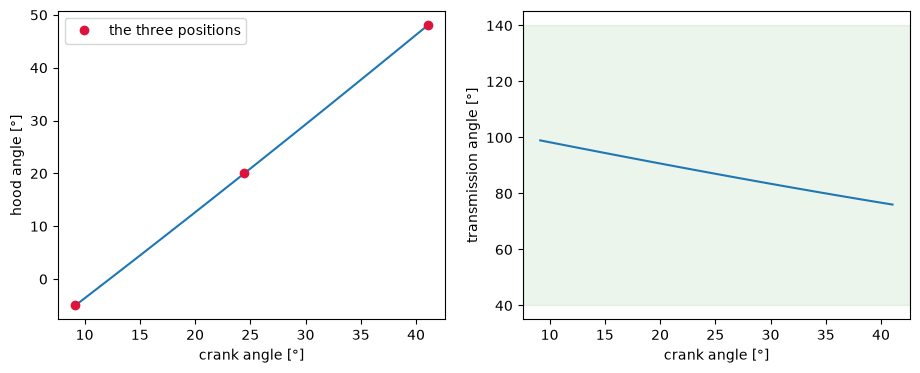

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(thetas, opening)
ax[0].plot([thetas[k] for k in at.values()], [t for _, t in poses.values()], "o", color="crimson",
           label="the three positions")
ax[0].set_xlabel("crank angle [°]")
ax[0].set_ylabel("hood angle [°]")
ax[0].legend()
ax[1].plot(thetas, transmission)
ax[1].axhspan(40, 140, color="green", alpha=0.08)
ax[1].set_xlabel("crank angle [°]")
ax[1].set_ylabel("transmission angle [°]")
plt.show()

## The hood and the windshield

The hood panel is a spline through its outer surface, offset with `Offset` to a 20 mm thick band, and the bracket is
a plate around the moving pivots. Both are made once in the hood's own coordinates and placed in each position by
`Rotated` and `Translated`. The windshield starts 110 mm behind the closed hood and rises at 25°. The gap between the
moving hood and the windshield is measured with `Distance` in every position.

In [12]:
panel = px.Spline([(0, 0), (350, 18), (750, 10), (1150, -60)]).Offset(10)
plate = px.FromPolyline([(10, -5), (115, -5), pivots["A"], pivots["B"]], closed=True).Face()
holes = [px.QuickSketch().Circle(*pivots[n], 6).Face() for n in "AB"]
plate = px.Subtract([px.Unify([plate, plate.outer.Offset(10)]), *holes])
windshield = px.Line((-110, 10), (-110 - 900 * math.cos(math.radians(25)), 10 + 900 * math.sin(math.radians(25))))


def placed(shape, m):
    t = angle_of(m["P"], m["Q"])
    return shape.Rotated((0, 0), t).Translated(m["P"])


gaps = [placed(panel, m).faces[0].outer.Distance(windshield) for m in motion]
print("smallest gap between hood and windshield", round(min(gaps), 1), "mm, at a hood angle of",
      round(opening[int(np.argmin(gaps))], 1), "degrees")

smallest gap between hood and windshield 26.1 mm, at a hood angle of 48.0 degrees


The hood in its three positions and on the way, and the hinge close up:

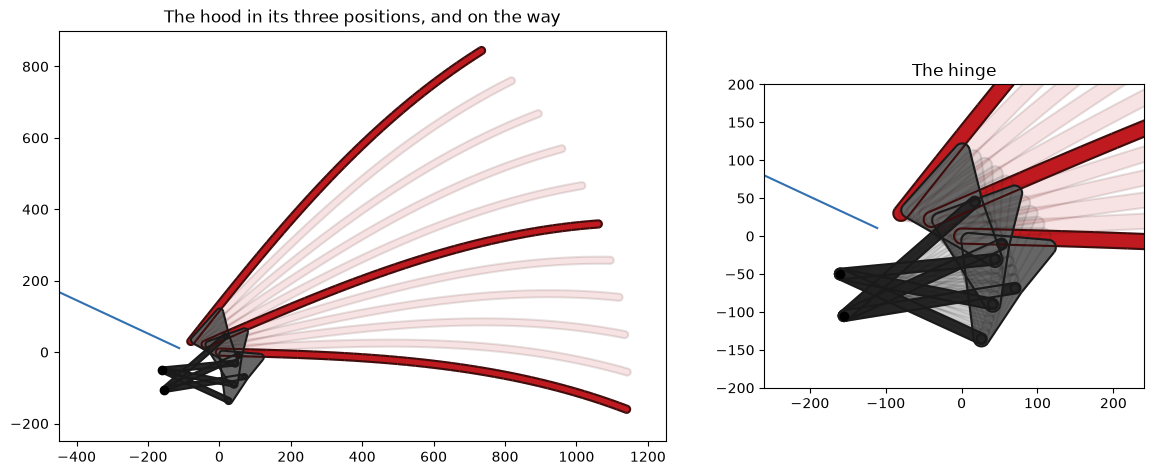

In [13]:
def draw(ax, m, alpha=1.0, linkage=True):
    edge = (0.25, 0.05, 0.05, alpha)
    px.Plot(placed(panel, m), ax=ax, face_col=(0.75, 0.1, 0.12, alpha), line_col=edge, arc_col=edge, spline_col=edge,
            legend=False)
    if linkage:
        edge = (0.1, 0.1, 0.1, alpha)
        px.Plot(placed(plate, m), ax=ax, face_col=(0.4, 0.4, 0.4, alpha), line_col=edge, arc_col=edge,
                spline_col=edge, legend=False)
        for g, p in ((ground["A"], m["A"]), (ground["B"], m["B"])):
            px.Plot(px.Line(g, p).Offset(7), ax=ax, face_col=(0.15, 0.15, 0.15, alpha), line_col=edge, arc_col=edge,
                    legend=False)


fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
views = (((-450, 1250), (-250, 900)), ((-260, 240), (-200, 200)))
for ax, (xlim, ylim), ghosts in zip(axs, views, (False, True)):
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    for m in motion[::6]:
        draw(ax, m, alpha=0.12, linkage=ghosts)
    for k in at.values():
        draw(ax, motion[k])
    px.Plot(windshield, ax=ax, line_col="#3070b0", legend=False)
    ax.plot(*zip(*ground.values()), "o", color="k")
axs[0].set_title("The hood in its three positions, and on the way")
axs[1].set_title("The hinge")
plt.show()

The hood opening and closing:

In [14]:
plt.rcParams["animation.frame_format"] = "jpeg"
fig, ax = plt.subplots(figsize=(9, 5))
cycle = motion + motion[::-1]


def frame(k):
    ax.clear()
    ax.set_xlim(-450, 1250)
    ax.set_ylim(-250, 900)
    px.Plot(windshield, ax=ax, line_col="#3070b0", legend=False)
    draw(ax, cycle[k])
    ax.set_title(f"Hood at {angle_of(cycle[k]['P'], cycle[k]['Q']):.1f}°")


animation = FuncAnimation(fig, frame, frames=len(cycle), interval=50)
plt.close(fig)
HTML(animation.to_jshtml())

In [15]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
save_animation(animation, "hood-hinge", still=False, bare=True)
frame(60)
save_figure(fig, "hood-hinge", bare=True)